# 04 — Detecting the poisoned training samples

**The defender's situation.** The defender received a training set (23,880 images) and trained the model on it, without knowing that 24 Stop images carry a trigger and were relabelled as Speed limit 80. They have three things: this training set with its labels, the trained model, and the small clean validation set. They do **not** know which samples are poisoned, nor which class is the target.

The three detection methods below look at what the model has learned: the activations of its **last hidden layer** (256 units, `model.features()`). The idea (Chen et al., 2018) is that a poisoned image labelled Speed limit 80 is still a Stop sign: the model must use a different internal reason (the trigger) to put it in that class, so its activations sit apart from those of genuine Speed limit 80 signs.

**Golden rule.** The detection methods never use the true poison indices, neither to decide nor to choose a parameter. All parameters are fixed beforehand in `configs/base.yaml` (section `detection`) and justified below. The poison record is opened only at the end, to *evaluate* a detection that is already finished.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd

from src.config import load_config, resolve_path
from src.data import GTSRB_CLASS_NAMES, load_gtsrb, load_train_groups, train_val_split
from src.detection import run_detection
from src.experiment import compare_art_cluster_analyses, detection_rows, load_poisoned_run, score_detection
from src.plots import plot_detection_errors, plot_detection_summary, plot_flagged_per_class, plot_target_class_pca
from src.utils import save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir = resolve_path(cfg, "figures_dir"), resolve_path(cfg, "metrics_dir")
source, target = cfg["backdoor"]["source_class"], cfg["backdoor"]["target_class"]
num_classes = cfg["data"]["num_classes"]
METHODS = {"clustering": "Activation clustering (ours)", "art": "ART ActivationDefence", "centroid": "Distance to centroid"}

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


## 1. Parameters, fixed before looking at any result

| method | parameters | why |
|---|---|---|
| Activation clustering (ours) | per class: PCA to 10 dims, KMeans with 2 clusters, flag the smaller cluster if it holds less than 35% of the class | the values of Chen et al. (2018), also ART's defaults: a class without poison should split into two comparable halves, a poisoned class into a big clean cluster and a small poisoned one |
| ART ActivationDefence | same clustering, `cluster_analysis="relative-size"` (threshold 0.35) | the paper's criterion and the same rule as our version, so the two can be compared; `"smaller"` would flag the smaller cluster of *every* class by construction |
| Distance to centroid | per class: PCA to 10 dims, z-score of the distance to the class centroid, flag z > 3 | classic outlier rule: for a normal distribution about 0.13% of points lie above 3 standard deviations |

ART's `ActivationDefence` takes the activations of the **last** layer of the classifier. For our model that is the 43-unit output layer, not the 256-unit hidden layer of the paper. `src/detection.py` makes it read the hidden layer (`fc`), and a test checks that these activations equal `model.features()`.

## 2. Data: the training set the defender received

The clean training split is rebuilt as in the previous notebooks, then the saved poison record is applied to recreate exactly the poisoned training set that `poisoned_r05` was trained on. In a real situation the defender would simply receive this set; here the record is only used to rebuild it and, at the end, to score the detection. The detection functions receive `x_defender, y_defender` and the model, nothing else.

In [2]:
x_full, y_full, _, _ = load_gtsrb(cfg)
x_train, y_train, _, _ = train_val_split(x_full, y_full, load_train_groups(cfg), cfg["data"]["val_ratio"], cfg["seed"])
main_name, model, x_defender, y_defender, record, _ = load_poisoned_run(x_train, y_train, cfg, cfg["backdoor"]["poison_rate"])
print(f"{main_name}: {len(y_defender)} training images, model loaded (no retraining)")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


poisoned_r05: 23880 training images, model loaded (no retraining)


## 3. Running the three detection methods

`run_detection` extracts the activations of the last hidden layer for all training images and runs the three methods. It receives only the training images, their labels and the model.

In [3]:
detection = run_detection(model, x_defender, y_defender, cfg)
pd.Series({METHODS[m]: int(s.sum()) for m, s in detection["suspects"].items()}).to_frame("flagged samples")

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


,flagged samples
Activation clustering (ours),1142
ART ActivationDefence,1013
Distance to centroid,260


## 4. Why it can work: the target class seen by the model

From here on we use the poison record to **evaluate**. The figure projects to 2D the activations of all training samples labelled Speed limit 80 (1,140 genuine signs plus the 24 poisoned Stop images). Blue: clean, red: poisoned (ground truth, shown for explanation only). The circles are the samples flagged by each method.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/pca_target_class.png


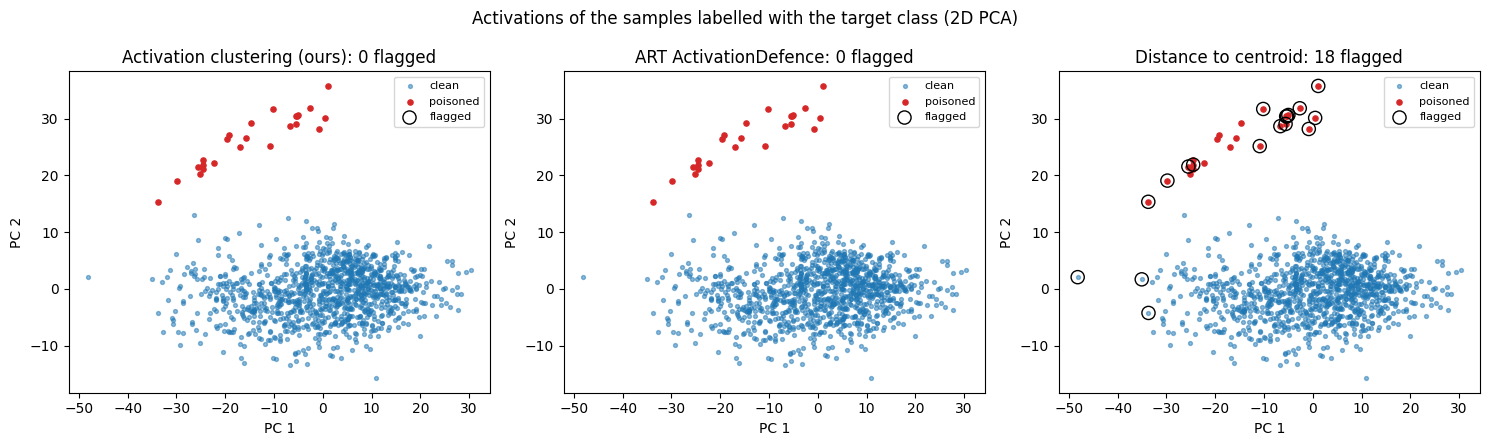

In [4]:
poison_idx = np.array(record["indices"])
is_poison = np.zeros(len(y_defender), dtype=bool)
is_poison[poison_idx] = True
in_target = y_defender == target
plot_target_class_pca(
    detection["activations"][in_target], is_poison[in_target],
    {METHODS[m]: s[in_target] for m, s in detection["suspects"].items()},
    path=figures_dir / "pca_target_class.png",
);

## 5. Scores

In simple words:
- a **true positive** (TP) is a poisoned image that was flagged; a **false positive** (FP) is a clean image wrongly flagged; a **false negative** (FN) is a poisoned image that was missed;
- **precision** = TP / flagged: when the method raises an alarm, how often is it right? Low precision means many clean images would be thrown away;
- **recall** = TP / poisoned: which share of the poison was found? Low recall means poison stays in the training set;
- **F1** combines both (harmonic mean): it is high only if both are high.

For remediation, recall matters most (every missed image can keep the backdoor alive), but a very low precision costs clean training data.

In [5]:
results = {main_name: score_detection(main_name, detection["suspects"], y_defender, record, cfg)}
summary = detection_rows(main_name, results[main_name])
pd.DataFrame(summary).assign(method=lambda d: d["method"].map(METHODS)).set_index("method").drop(columns="run_name").round(3)

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_clustering_poisoned_r05.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_poisoned_r05.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_centroid_poisoned_r05.json


,n_flagged,tp,fp,fn,precision,recall,f1,flagged_in_target_class
method,,,,,,,,
Activation clustering (ours),1142,0,1142,24,0.000,0.000,0.000,0
ART ActivationDefence,1013,0,1013,24,0.000,0.000,0.000,0
Distance to centroid,260,15,245,9,0.058,0.625,0.106,18


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/detection_summary.png


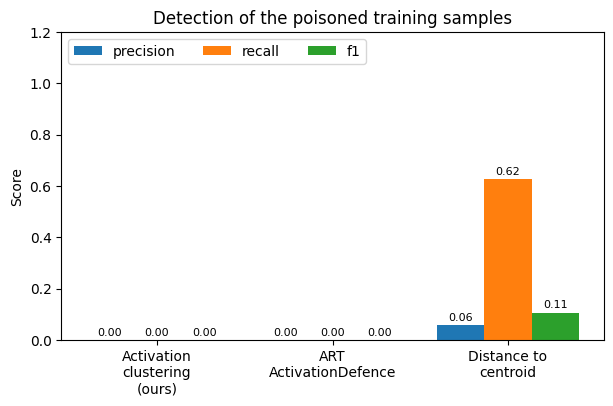

In [6]:
plot_detection_summary(
    [{"method": METHODS[m], **r} for m, r in results[main_name].items()], figures_dir / "detection_summary.png"
);

## 6. Where do the false positives come from, and what is missed?

Flagged samples per training label: a method that works only flags samples in the target class (5).

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/flagged_per_class.png


,classes with flags,flags outside the target class
Activation clustering (ours),10,1142
ART ActivationDefence,9,1013
Distance to centroid,38,242


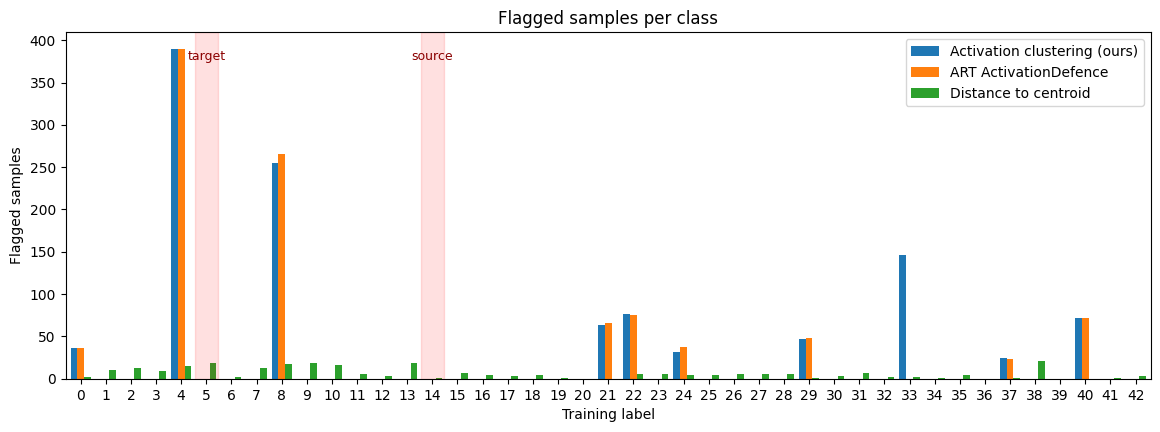

In [7]:
plot_flagged_per_class(
    {METHODS[m]: r["flagged_per_class"] for m, r in results[main_name].items()}, num_classes,
    highlight={source: "source", target: "target"}, path=figures_dir / "flagged_per_class.png",
);
pd.DataFrame(
    {METHODS[m]: {"classes with flags": len(r["flagged_per_class"]),
                  "flags outside the target class": r["n_flagged"] - r["flagged_in_target_class"]}
     for m, r in results[main_name].items()}
).T

Our clustering method splits every class into two clusters. The table lists the classes where the smaller cluster fell under the 35% threshold, plus the target class whatever its result, with the silhouette score (how well separated the two clusters are, from -1 to 1).

In [8]:
info = detection["clustering_info"]
pd.DataFrame(
    [{"class": f"{c}: {GTSRB_CLASS_NAMES[c]}", **i}
     for c, i in info.items() if i["flagged"] or c == target]
).round(3)

,class,cluster_sizes,smaller_share,silhouette,flagged
0,0: Speed limit (20km/h),"[36, 84]",0.300,0.457,True
1,4: Speed limit (70km/h),"[810, 390]",0.325,0.380,True
2,5: Speed limit (80km/h),"[443, 721]",0.381,0.313,False
3,8: Speed limit (120km/h),"[615, 255]",0.293,0.353,True
4,21: Double curve,"[146, 64]",0.305,0.386,True
5,22: Bumpy road,"[164, 76]",0.317,0.344,True
6,24: Road narrows on the right,"[118, 32]",0.213,0.385,True
7,29: Bicycles crossing,"[103, 47]",0.313,0.452,True
8,33: Turn right ahead,"[274, 146]",0.348,0.408,True
9,37: Go straight or left,"[96, 24]",0.200,0.398,True


A few errors of each method: false positives (clean images flagged) and false negatives (poisoned images missed), with their training label.

/home/mdev/Dev/school/SD/gtsrb-data-poisoning/src/plots.py:324: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/detection_errors.png


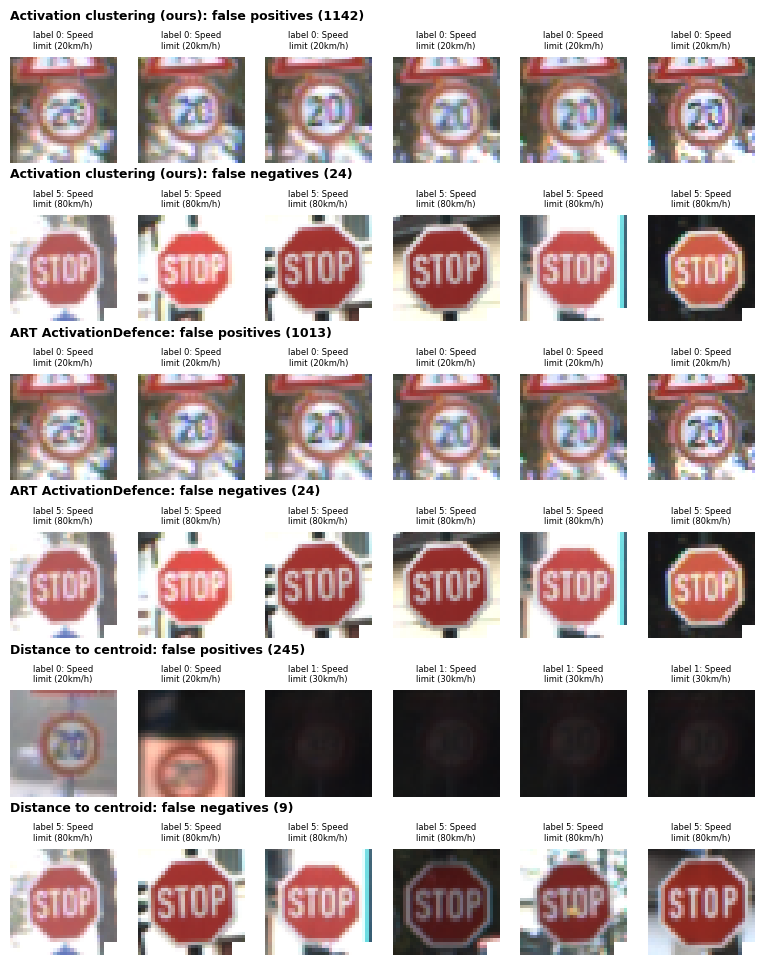

In [9]:
plot_detection_errors(
    x_defender, y_defender,
    {METHODS[m]: (r["false_positive_indices"], r["false_negative_indices"]) for m, r in results[main_name].items()},
    GTSRB_CLASS_NAMES, n=6, path=figures_dir / "detection_errors.png",
);

## 7. The same detection at 10% poisoning

Same parameters, same code, on the 10% poisoned training set (48 poisoned images) and the model trained on it.

In [10]:
runs = {main_name: (model, x_defender, y_defender, record, cfg)}
for rate in cfg["attack"]["extra_poison_rates"]:
    name, rate_model, x_rate, y_rate, rate_record, rate_cfg = load_poisoned_run(x_train, y_train, cfg, rate)
    runs[name] = (rate_model, x_rate, y_rate, rate_record, rate_cfg)
    rate_detection = run_detection(rate_model, x_rate, y_rate, rate_cfg)
    results[name] = score_detection(name, rate_detection["suspects"], y_rate, rate_record, rate_cfg)
    summary += detection_rows(name, results[name])

save_json({"parameters": cfg["detection"], "rows": summary}, metrics_dir / "detection_summary.json")
pd.DataFrame(summary).set_index(["run_name", "method"]).round(3)

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_clustering_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_centroid_poisoned_r10.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_summary.json


n_flagged  tp    fp  fn  precision  recall     f1  \
run_name     method                                                          
poisoned_r05 clustering       1142   0  1142  24      0.000   0.000  0.000   
             art              1013   0  1013  24      0.000   0.000  0.000   
             centroid          260  15   245   9      0.058   0.625  0.106   
poisoned_r10 clustering       1386  48  1338   0      0.035   1.000  0.067   
             art              1019  48   971   0      0.047   1.000  0.090   
             centroid          270  12   258  36      0.044   0.250  0.075   

                         flagged_in_target_class  
run_name     method                               
poisoned_r05 clustering                        0  
             art                               0  
             centroid                         18  
poisoned_r10 clustering                      353  
             art                             324  
             centroid                         16

## 8. Secondary comparison: other ART cluster analyses (not used to choose)

ART offers other rules to decide which cluster is poisoned. They are reported here **for information only**: the method kept above (`relative-size`) was chosen beforehand, and this table, which uses the ground truth, must not be used to pick one.

In [11]:
comparison = [
    row for name, (m, x, y, rec, c) in runs.items() for row in compare_art_cluster_analyses(name, m, x, y, rec, c)
]
save_json({"note": "not used to choose the method", "rows": comparison},
          metrics_dir / "detection_art_cluster_analysis_comparison.json")
pd.DataFrame(comparison).set_index(["run_name", "cluster_analysis"]).round(3)

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.4567


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3798


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3479


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3838


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3457


... (15 outputs left out)

INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.2588


INFO art.defences.detector.poison.clustering_analyzer: computed silhouette score: 0.3815


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_cluster_analysis_comparison.json


n_flagged  tp     fp  fn  precision  recall  \
run_name     cluster_analysis                                                 
poisoned_r05 smaller                 9662  21   9641   3      0.002   0.875   
             relative-size           1013   0   1013  24      0.000   0.000   
             distance               23640  24  23616   0      0.001   1.000   
             silhouette-scores       3270   0   3270  24      0.000   0.000   
poisoned_r10 smaller                 9632  48   9584   0      0.005   1.000   
             relative-size           1019  48    971   0      0.047   1.000   
             distance               23651  48  23603   0      0.002   1.000   
             silhouette-scores       3678  48   3630   0      0.013   1.000   

                                   f1  flagged_in_target_class  
run_name     cluster_analysis                                   
poisoned_r05 smaller            0.004                      439  
             relative-size      0.000                        0  
             distance           0.002                     1164  
             silhouette-scores  0.000                        0  
poisoned_r10 smaller            0.010                      324  
             relative-size      0.090                      324  
             distance           0.004                     1188  
             silhouette-scores  0.026                     1188

## 9. Conclusion

Measured with the parameters fixed beforehand (section 1), on the models trained in notebook 03.

**With these a-priori parameters, detection largely fails. This is the main result of this step, and the parameters are not changed after looking at the ground truth.**

- **Activation clustering (ours and ART), 5%: 0 of the 24 poisoned images found, and about 1,000 clean images flagged** (1,142 for ours, 1,013 for ART). This is not because the poison is invisible: the PCA figure shows that the 24 poisoned images form a separate group inside the target class. The method asks KMeans to cut each class in two. The poisoned images are only 2.1% of the samples labelled Speed limit 80 (24 out of 1,164), so the cut that best reduces KMeans' error splits the large clean group instead (443 / 721 samples). The smaller part holds 38% of the class, above the 35% threshold, so the target class is not flagged. Meanwhile about ten clean classes naturally split into unequal parts (lighting, viewing distance, sign variants) and are flagged: all their flags are false positives.
- **Activation clustering, 10%: all 48 poisoned images found, but with very low precision** (3.5% ours, 4.7% ART). With 4.0% of poison in the target class, the smaller cluster drops to 30% (353 samples) and is flagged. It contains the 48 poisoned images and 305 genuine Speed limit 80 signs, and the same clean classes as before are flagged too.
- **The share that matters for detection is not the poisoning rate.** The rate is defined on the source class (5% of the Stop images), but these methods look at the samples labelled with the target class, where the poison is diluted to 2.1% (5%) and 4.0% (10%).
- **Distance to centroid gives the best F1 at 5%** (recall 62.5%: 15 of 24 found; precision 5.8%). It flags about 1% of every class (245 false positives in 38 classes) instead of the 0.13% expected from a normal distribution, because distances to the centroid have a heavy tail: very dark, blurred or unusual images are far from their class centre. At 10% its recall drops to 25%: the 48 poisoned images raise the mean and spread of their class's distances, so their own z-scores shrink (median 3.4 at 5%, 2.4 at 10%). More poison hides itself better against this rule.
- **Our clustering and ART's agree** on whether the target class is flagged (not at 5%; at 10% with 353 and 324 samples) and on most other flagged classes. The small differences come from KMeans initialisation (10 seeded starts for ours, scikit-learn's default single start for ART).
- **ART's other cluster analyses do not help** (secondary table): `smaller` and `distance` flag 40% to 99% of the training set. They were not used to choose anything.

For remediation, removing the suspects of these methods would either leave the poison in place (clustering at 5%) or throw away about a thousand clean images. One legitimate improvement, within the golden rule, would be to calibrate the thresholds on the clean validation set (the defender's trusted data), for example by measuring how many clean samples each rule flags there. That is a decision for the next step.
